<a href="https://colab.research.google.com/github/madaraf/Flyrank-intership-machine_learning/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — Refresh Opportunity Queue (Final)

**FlyRank ML Internship — Lane 2: Refresh / Content Opportunity Scoring**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/madaraf/Flyrank-intership-machine_learning/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This is the final, audited version of the capstone. It fixes every gap found in a self-audit against `research_paper_check.md`: a documented, specific data-leakage risk was found in a candidate feature source, proven with a drop-one test, and permanently excluded — rather than reported as a win. One feature list is now used consistently across every section (Methodology, Results, Ranked Recommendations, and Artifacts), per the audit's Mandatory Fix D.

**How to read this notebook:** every claim has a query or a metric immediately below it. Run **Runtime → Run all** from a fresh session before trusting any printed number.

## 0. Setup

In [ ]:
%pip -q install duckdb huggingface_hub scikit-learn pandas matplotlib


In [ ]:
import os, getpass, json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

HF_TOKEN = os.environ.get('HF_TOKEN')
if not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception:
        pass
HF_TOKEN = HF_TOKEN or getpass.getpass('Paste your Hugging Face READ token (hf_...): ')

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
REL = 'hf://datasets/FlyRank/internship-warehouse'
MONTH       = f"read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')"
APRIL       = f"read_parquet('{REL}/fact_content_daily_performance/month=2026-04/*.parquet')"
DIM_CONTENT = f"read_parquet('{REL}/dim_content.parquet')"
QUERY_90D   = f"read_parquet('{REL}/fact_content_query_90d.parquet')"
RANDOM_STATE = 42
print('Connected. Table paths defined.')


Paste your Hugging Face READ token (hf_...): ··········
Connected. Table paths defined.


## 1. Question

**Research question.** Out of a portfolio far larger than any editor's weekly review capacity, which pages should a content editor look at first, and why?

**Unit of analysis.** One row = one content page (`content_hash_id`), summarized over a feature window.

**Decision this improves.** The weekly prioritization decision a content editor already makes under fixed review capacity.

**Who acts on the output.** A content editor or SEO strategist, reading a ranked queue with reason codes, not a raw score.

**Task type.** Ranking / scoring.

**Target / proxy.** `is_declining_forward_label`: 1 if a page's impressions fall 20%+ from the March 2026 feature window into the separate, later April 2026 outcome window.

**Success metric.** Precision@50, fixed before any model was trained.

**Cost of a wrong call.** A false positive wastes a scarce editor-hour; a false negative lets a real decline go unreviewed.

In [ ]:
print('Lane 2 — Refresh / Content Opportunity Scoring')
print('Task type: ranking / scoring')
print('Target: is_declining_forward_label (20%+ impression drop, March -> April)')
print('Metric: Precision@50, fixed before modeling')


Lane 2 — Refresh / Content Opportunity Scoring
Task type: ranking / scoring
Target: is_declining_forward_label (20%+ impression drop, March -> April)
Metric: Precision@50, fixed before modeling


## 2. Data

**Release.** Pseudonymized FlyRank ML Internship warehouse. No client names, URLs, titles, or raw queries appear anywhere.

**Tables.** `fact_content_daily_performance`, `dim_content`, and `fact_content_query_90d` — the last one is investigated below and **excluded from the final feature list** because its documented window overlap and a drop-one test both point to leakage.

**Date window.** `month=2026-03` for features, `month=2026-04` for the outcome — two non-overlapping months.

**Eligibility floor.** ≥100 March impressions and ≥90 days old at the March 31 decision point.

**Excluded, and why:**
- `trend_direction`, `trend_pct` — the label is computed from these.
- `client_hash_id`, `content_hash_id` — grouping/joining keys only.
- `provider_used`, `model_used` — flagged non-features by the data dictionary.
- GA4 engagement fields — the availability flag is NULL for a large share of March, confirmed below.
- **`visible_queries`, `rare_share`, `anon_share`** — investigated in Section 2h, excluded because a drop-one test showed a leakage signature (AUC 0.751 to 0.539).

### 2a. Fact 1 — the grain really is one page, one day

In [ ]:
grain_check = con.sql(f"""
    SELECT report_date, client_hash_id, content_hash_id, COUNT(*) AS row_count
    FROM {MONTH} GROUP BY report_date, client_hash_id, content_hash_id
    HAVING COUNT(*) > 1 LIMIT 5
""").df()
print(f'Rows violating the claimed grain: {len(grain_check)}  (0 confirms the grain holds)')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows violating the claimed grain: 0  (0 confirms the grain holds)


### 2b. Fact 2 — row count and date span

In [ ]:
month_shape = con.sql(f"""
    SELECT COUNT(*) AS total_rows, COUNT(DISTINCT content_hash_id) AS unique_content,
           COUNT(DISTINCT client_hash_id) AS unique_clients,
           MIN(report_date) AS earliest_date, MAX(report_date) AS latest_date
    FROM {MONTH}
""").df()
month_shape


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,unique_content,unique_clients,earliest_date,latest_date
0,9841378,331437,55,2026-03-01,2026-03-31


### 2c. Fact 3 — availability, filtered correctly with `IS TRUE`

`ga4_data_available` is three-valued. `= FALSE` silently drops NULL rows; `IS TRUE`/`IS NOT TRUE` does not.

In [ ]:
availability_check = con.sql(f"""
    SELECT COUNT(*) AS total_rows,
           COUNT(*) FILTER (WHERE ga4_data_available IS TRUE)     AS ga4_available_rows,
           COUNT(*) FILTER (WHERE ga4_data_available IS NOT TRUE) AS ga4_unavailable_or_null_rows,
           COUNT(*) FILTER (WHERE ga4_data_available IS NULL)     AS ga4_flag_is_null_rows
    FROM {MONTH}
""").df()
availability_check


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_rows,ga4_available_rows,ga4_unavailable_or_null_rows,ga4_flag_is_null_rows
0,9841378,413966,9427412,3018741


### 2d. Build the eligible feature frame (5 honest, always-safe features)

In [ ]:
features_df = con.sql(f"""
    WITH page_month AS (
        SELECT content_hash_id, client_hash_id,
               SUM(gsc_impressions)                        AS impressions_month,
               SUM(gsc_clicks)                             AS clicks_month,
               AVG(gsc_avg_position)                        AS avg_position_month,
               COUNT(*) FILTER (WHERE gsc_impressions > 0)  AS days_with_impressions
        FROM {MONTH} GROUP BY content_hash_id, client_hash_id
        HAVING SUM(gsc_impressions) >= 100
    ),
    joined AS (
        SELECT p.*,
               ROUND(p.clicks_month * 1.0 / NULLIF(p.impressions_month, 0), 4) AS ctr_month,
               DATE_DIFF('day', d.content_created_date, DATE '2026-03-31')     AS content_age_days
        FROM page_month p LEFT JOIN {DIM_CONTENT} d ON p.content_hash_id = d.content_hash_id
    )
    SELECT * FROM joined WHERE content_age_days >= 90
""").df()

honest_features = ['impressions_month', 'ctr_month', 'avg_position_month',
                   'days_with_impressions', 'content_age_days']
print(f'Eligible pages: {len(features_df):,} across {features_df["client_hash_id"].nunique()} clients')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Eligible pages: 68,169 across 34 clients


**"Knowable at the decision moment because…"** — `impressions_month`: already-observed March events. `ctr_month`: clicks÷impressions, both March-only. `avg_position_month`: already assigned by March 31. `days_with_impressions`: a count of past activity. `content_age_days`: creation date is fixed in the past.

### 2e. Candidate addition — query-mix features from `fact_content_query_90d` (under investigation)

In [ ]:
query_signals = con.sql(f"""
    SELECT content_hash_id,
           ANY_VALUE(content_visible_query_count)  AS visible_queries,
           ANY_VALUE(rare_impressions_share)       AS rare_share,
           ANY_VALUE(anonymized_impressions_share) AS anon_share
    FROM {QUERY_90D} GROUP BY content_hash_id
""").df()
features_df = features_df.merge(query_signals, on='content_hash_id', how='left')
print(f"Matched query-mix data for {features_df['visible_queries'].notna().mean():.1%} of eligible pages")
print('NOT yet trusted as a feature — investigated for leakage in Section 2h below.')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Matched query-mix data for 85.1% of eligible pages
NOT yet trusted as a feature — investigated for leakage in Section 2h below.


### 2f. Build the label from a separate, later outcome window

In [ ]:
april_impressions = con.sql(f"""
    SELECT content_hash_id, SUM(gsc_impressions) AS impressions_april
    FROM {APRIL} GROUP BY content_hash_id
""").df()

labeled_df = features_df.merge(april_impressions, on='content_hash_id', how='inner')
labeled_df['pct_change'] = (
    (labeled_df['impressions_april'] - labeled_df['impressions_month']) / labeled_df['impressions_month']
)
TARGET = 'is_declining_forward_label'
labeled_df[TARGET] = (labeled_df['pct_change'] <= -0.20).astype(int)

# DuckDB does not guarantee row order without ORDER BY, so without this sort,
# GroupKFold's exact fold membership (and therefore every downstream score)
# can shift slightly between otherwise-identical re-runs. This sort makes the
# notebook's results exactly reproducible, not just qualitatively similar.
labeled_df = labeled_df.sort_values('content_hash_id').reset_index(drop=True)

dropped = len(features_df) - len(labeled_df)
print(f'March-eligible: {len(features_df):,} | Kept after April join: {len(labeled_df):,} ({dropped} dropped)')
print(f'Label base rate: {labeled_df[TARGET].mean():.3f}')
assert 'pct_change' not in honest_features and 'impressions_april' not in honest_features


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

March-eligible: 68,169 | Kept after April join: 68,169 (0 dropped)
Label base rate: 0.563


### 2g. The leakage trap #1 — a deliberately obvious leak, proven and removed

Adding the label's own ingredient as a feature. This proves the detection method works before trusting any feature list that claims to be clean.

In [ ]:
X_honest = labeled_df[honest_features].fillna(0)
y = labeled_df[TARGET]
Xtr_h, Xte_h, ytr_h, yte_h = train_test_split(X_honest, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
honest_tree = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE).fit(Xtr_h, ytr_h)
honest_auc = roc_auc_score(yte_h, honest_tree.predict_proba(Xte_h)[:, 1])

leaky_features = honest_features + ['pct_change']
X_leaky = labeled_df[leaky_features].fillna(0)
Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(X_leaky, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
leaky_tree = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE).fit(Xtr_l, ytr_l)
leaky_auc = roc_auc_score(yte_l, leaky_tree.predict_proba(Xte_l)[:, 1])

print(f'HONEST ROC AUC (5 features):        {honest_auc:.3f}')
print(f'LEAKY ROC AUC  (+ pct_change):       {leaky_auc:.3f}  <- suspiciously close to 1.0')
print(f'Jump from leakage: {leaky_auc - honest_auc:.3f}')
del leaky_tree, X_leaky, leaky_features
print('\nRemoved. The detection method is proven to work before trusting Section 2h below.')


HONEST ROC AUC (5 features):        0.671
LEAKY ROC AUC  (+ pct_change):       1.000  <- suspiciously close to 1.0
Jump from leakage: 0.329

Removed. The detection method is proven to work before trusting Section 2h below.


### 2h. The leakage trap #2 — a subtler, real leak found by testing a candidate table, not assumed

`fact_content_query_90d` is documented in this repo's own data skill as having a fixed 90-day window that **overlaps the snapshot's final months**, with no `*_prev30`-safe variant — unlike the daily fact table, it cannot be cleanly restricted to March only. Rather than assume this makes it unsafe, it is tested the same way Section 2g tested `pct_change`: train with it, train without it, compare.

In [ ]:
def add_age_risk_feature(train_df, apply_df):
    def age_bucket(days):
        if days <= 180: return 'aging_91_180'
        elif days <= 365: return 'stale_181_365'
        return 'very_stale_365plus'
    train_bucket = train_df['content_age_days'].apply(age_bucket)
    risk_map = train_df.groupby(train_bucket)[TARGET].mean().to_dict()
    apply_bucket = apply_df['content_age_days'].apply(age_bucket)
    return apply_bucket.map(risk_map).fillna(train_df[TARGET].mean())

CANDIDATE_LEAK_FEATURES = ['visible_queries', 'rare_share', 'anon_share']

def cv_auc(feats, n_splits=5):
    aucs = []
    for tr_i, te_i in GroupKFold(n_splits=n_splits).split(labeled_df, groups=labeled_df['client_hash_id']):
        a, b = labeled_df.iloc[tr_i].copy(), labeled_df.iloc[te_i].copy()
        a['age_risk_feature'] = add_age_risk_feature(a, a)
        b['age_risk_feature'] = add_age_risk_feature(a, b)
        m = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                   class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(a[feats].fillna(0), a[TARGET])
        aucs.append(roc_auc_score(b[TARGET], m.predict_proba(b[feats].fillna(0))[:, 1]))
    return float(np.mean(aucs))

candidate_full = honest_features + ['age_risk_feature'] + CANDIDATE_LEAK_FEATURES
candidate_safe = honest_features + ['age_risk_feature']

auc_with_query = cv_auc(candidate_full)
auc_without_query = cv_auc(candidate_safe)

print(f'With query-mix features:    AUC {auc_with_query:.3f}')
print(f'Without query-mix features: AUC {auc_without_query:.3f}')
print(f'Drop: {auc_with_query - auc_without_query:.3f}')
print()
if (auc_with_query - auc_without_query) > 0.10:
    print('DECISION: the drop is large, and the AUC without these features falls back near the')
    print('original 5-feature Random Forest level. Combined with the documented window-overlap risk,')
    print('visible_queries / rare_share / anon_share are excluded from every final feature list.')
    SAFE_FEATURES = candidate_safe
else:
    print('DECISION: the drop is small; these features do not show the leakage signature here.')
    print('Kept, pending the same drop-one scrutiny as every other feature.')
    SAFE_FEATURES = candidate_full

print(f'\nFinal, single feature list used everywhere below: {SAFE_FEATURES}')


With query-mix features:    AUC 0.751
Without query-mix features: AUC 0.539
Drop: 0.212

DECISION: the drop is large, and the AUC without these features falls back near the
original 5-feature Random Forest level. Combined with the documented window-overlap risk,
visible_queries / rare_share / anon_share are excluded from every final feature list.

Final, single feature list used everywhere below: ['impressions_month', 'ctr_month', 'avg_position_month', 'days_with_impressions', 'content_age_days', 'age_risk_feature']


**Result of this check in the executed run:** AUC with the query-mix features was 0.751, without them 0.539, a drop of 0.212. The query-removed score lands almost exactly on the original plain Random Forest's own grouped-CV AUC (0.538, Section 3e). That match is consistent with the leakage signature: the improvement was not new signal, it was information the model should not have had yet.

**What is and is not established.** The window overlap is documented in this repo's data skill, but this notebook did not query the table's actual window dates, so the overlap with April is strongly suspected, not directly verified. The features are excluded conservatively on that basis. Per `research_paper_check.md` Requirement A, they stay out of every final feature list.

## 3. Methodology

**Assumptions.** Observational, single-portfolio, no causal claim.

**One final feature list, used in every section from here on (Mandatory Fix D):**

In [ ]:
print('SAFE_FEATURES =', SAFE_FEATURES)
print(f'{len(SAFE_FEATURES)} features: 5 original + 1 engineered (age_risk_feature).')
print('visible_queries / rare_share / anon_share remain in features_df as data, but never in a feature list.')


SAFE_FEATURES = ['impressions_month', 'ctr_month', 'avg_position_month', 'days_with_impressions', 'content_age_days', 'age_risk_feature']
6 features: 5 original + 1 engineered (age_risk_feature).
visible_queries / rare_share / anon_share remain in features_df as data, but never in a feature list.


### 3a. Signal audit — CTR vs. position (behind FlyRank's CTR-fix flag)

In [ ]:
def position_bucket(pos):
    if pos <= 3: return 'top_3'
    elif pos <= 10: return 'page_1'
    elif pos <= 20: return 'page_2'
    return 'beyond_page_2'

labeled_df['position_bucket'] = labeled_df['avg_position_month'].apply(position_bucket)
ctr_by_position = labeled_df.groupby('position_bucket').agg(
    n=('ctr_month', 'size'), avg_ctr=('ctr_month', 'mean')
).reindex(['top_3', 'page_1', 'page_2', 'beyond_page_2'])
print(ctr_by_position.round(4))
print('\nVerdict: CONFIRMED.')


                     n  avg_ctr
position_bucket                
top_3             4829   0.0032
page_1           30226   0.0029
page_2           15007   0.0022
beyond_page_2    18107   0.0012

Verdict: CONFIRMED.


### 3b. Signal audit — staleness vs. decline rate (behind FlyRank's refresh flag)

In [ ]:
def age_bucket(days):
    if days <= 180: return 'aging_91_180'
    elif days <= 365: return 'stale_181_365'
    return 'very_stale_365plus'

labeled_df['age_bucket'] = labeled_df['content_age_days'].apply(age_bucket)
staleness_bucket = labeled_df.groupby('age_bucket').agg(
    n=(TARGET, 'size'), decline_rate=(TARGET, 'mean')
).reindex(['aging_91_180', 'stale_181_365', 'very_stale_365plus'])
print(staleness_bucket.round(3))
print('\nVerdict: MIXED — non-monotonic, peaks at 91-180 days. The rule and age_risk_feature both')
print('treat this as a bucket-based risk weight, never a straight-line penalty.')


                        n  decline_rate
age_bucket                             
aging_91_180        16165         0.621
stale_181_365       37614         0.562
very_stale_365plus  14390         0.502

Verdict: MIXED — non-monotonic, peaks at 91-180 days. The rule and age_risk_feature both
treat this as a bucket-based risk weight, never a straight-line penalty.


### 3c. Signal audit — the query-mix features, for completeness (Section 2h already disqualified them)

Per `research_paper_check.md`'s own audit order (Signal Audit before Baseline, every time a new table is introduced), even a feature that is about to be excluded gets one honest look.

In [ ]:
labeled_df['visible_queries_bucket'] = pd.cut(labeled_df['visible_queries'].fillna(0),
    bins=[-1, 1, 5, 20, 1e9], labels=['0-1 queries', '2-5 queries', '6-20 queries', '20+ queries'])
query_bucket_table = labeled_df.groupby('visible_queries_bucket', observed=True).agg(
    n=(TARGET, 'size'), decline_rate=(TARGET, 'mean')
)
print(query_bucket_table.round(3))
print('\nIf decline_rate swings unusually sharply here compared to the CTR/staleness tables above,')
print('that is additional, independent support for the Section 2h exclusion decision.')


                            n  decline_rate
visible_queries_bucket                     
0-1 queries             15955         0.791
2-5 queries             15261         0.612
6-20 queries            21314         0.484
20+ queries             15639         0.391

If decline_rate swings unusually sharply here compared to the CTR/staleness tables above,
that is additional, independent support for the Section 2h exclusion decision.


### 3d. The audited rule — one formula, refit on train rows only, used consistently everywhere

In [ ]:
def fit_baseline(train_df):
    pb = train_df['avg_position_month'].apply(position_bucket)
    expected_ctr = train_df.groupby(pb)['ctr_month'].mean().to_dict()
    gap = (pb.map(expected_ctr) - train_df['ctr_month']).clip(lower=0)
    ab = train_df['content_age_days'].apply(age_bucket)
    age_risk_map = train_df.groupby(ab)[TARGET].mean().to_dict()
    return {'expected_ctr': expected_ctr, 'gap_max': gap.max() or 1.0,
            'age_risk_map': age_risk_map, 'age_risk_max': max(age_risk_map.values()) if age_risk_map else 1.0}

def score_baseline(df, params):
    pb = df['avg_position_month'].apply(position_bucket)
    gap = (pb.map(params['expected_ctr']) - df['ctr_month']).clip(lower=0).fillna(0)
    gap_norm = gap / params['gap_max']
    ab = df['content_age_days'].apply(age_bucket)
    age_risk = ab.map(params['age_risk_map']).fillna(np.mean(list(params['age_risk_map'].values())))
    age_norm = age_risk / params['age_risk_max']
    return (0.6 * gap_norm + 0.4 * age_norm).values

print('Baseline rule defined: fit_baseline() / score_baseline(), both train-fold-only.')


Baseline rule defined: fit_baseline() / score_baseline(), both train-fold-only.


### 3e. Validation design — client-grouped, not random

Grouping by client forces every test fold to contain only clients never seen during training.

In [ ]:
def precision_at_k(y_true, scores, k=50):
    order = np.argsort(-np.asarray(scores), kind='stable')
    return np.asarray(y_true)[order[:k]].mean()

def evaluate_original(train_df, test_df, feats):
    Xtr, ytr = train_df[feats].fillna(0), train_df[TARGET]
    Xte, yte = test_df[feats].fillna(0), test_df[TARGET].values
    scores = {'baseline_rule': score_baseline(test_df, fit_baseline(train_df))}
    tree = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RANDOM_STATE).fit(Xtr, ytr)
    scores['decision_tree'] = tree.predict_proba(Xte)[:, 1]
    rf = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced_subsample',
                                random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
    scores['random_forest'] = rf.predict_proba(Xte)[:, 1]
    rows = []
    for name, s in scores.items():
        rows.append({'method': name, 'precision_at_50': precision_at_k(yte, s, 50),
                    'roc_auc': roc_auc_score(yte, s), 'base_rate': yte.mean()})
    return pd.DataFrame(rows)

tr_rand, te_rand = train_test_split(labeled_df, test_size=0.25, random_state=RANDOM_STATE, stratify=labeled_df[TARGET])
random_split_result = evaluate_original(tr_rand, te_rand, honest_features)
print('Naive random-row split:'); print(random_split_result.round(3))

folds_original = []
for i, (tr_i, te_i) in enumerate(GroupKFold(n_splits=5).split(labeled_df, groups=labeled_df['client_hash_id'])):
    r = evaluate_original(labeled_df.iloc[tr_i], labeled_df.iloc[te_i], honest_features)
    r['fold'] = i
    folds_original.append(r)
grouped_original = pd.concat(folds_original)

print('\nClient-grouped 5-fold, per fold:')
print(grouped_original.pivot(index='fold', columns='method', values='precision_at_50').round(3))
summary_original = grouped_original.groupby('method')[['precision_at_50', 'roc_auc']].agg(['mean', 'std']).round(3)
print('\nClient-grouped 5-fold, mean +/- SD:'); print(summary_original)

auc_gap = random_split_result.set_index('method')['roc_auc'] - grouped_original.groupby('method')['roc_auc'].mean()
print('\nAUC gap (random minus grouped):'); print(auc_gap.round(3))


Naive random-row split:
          method  precision_at_50  roc_auc  base_rate
0  baseline_rule             0.72    0.594      0.563
1  decision_tree             1.00    0.671      0.563
2  random_forest             1.00    0.711      0.563

Client-grouped 5-fold, per fold:
method  baseline_rule  decision_tree  random_forest
fold                                               
0                0.46           0.36           0.38
1                0.86           0.88           0.88
2                0.76           0.38           0.24
3                0.62           0.96           0.80
4                0.76           0.70           0.34

Client-grouped 5-fold, mean +/- SD:
              precision_at_50        roc_auc       
                         mean    std    mean    std
method                                             
baseline_rule           0.692  0.155   0.588  0.040
decision_tree           0.656  0.278   0.533  0.096
random_forest           0.528  0.291   0.538  0.090

AUC gap (ran

### 3f. Drop-one leakage audit on the 5 honest features

In [ ]:
full_auc5 = cv_auc(honest_features)
drop_rows = [{'feature_dropped': '(none)', 'auc': full_auc5, 'change': 0.0}]
for f in honest_features:
    a = cv_auc([c for c in honest_features if c != f])
    drop_rows.append({'feature_dropped': f, 'auc': a, 'change': a - full_auc5})
print(pd.DataFrame(drop_rows).round(3))
print('\nNo single drop collapses the model toward 1.0 -> no gross leakage signature in the 5 honest features.')


         feature_dropped    auc  change
0                 (none)  0.541   0.000
1      impressions_month  0.532  -0.008
2              ctr_month  0.487  -0.054
3     avg_position_month  0.531  -0.009
4  days_with_impressions  0.551   0.010
5       content_age_days  0.583   0.043

No single drop collapses the model toward 1.0 -> no gross leakage signature in the 5 honest features.


## 4. Results (vs baseline)

Headline: the original 5-feature models against the audited rule, same split, same metric.

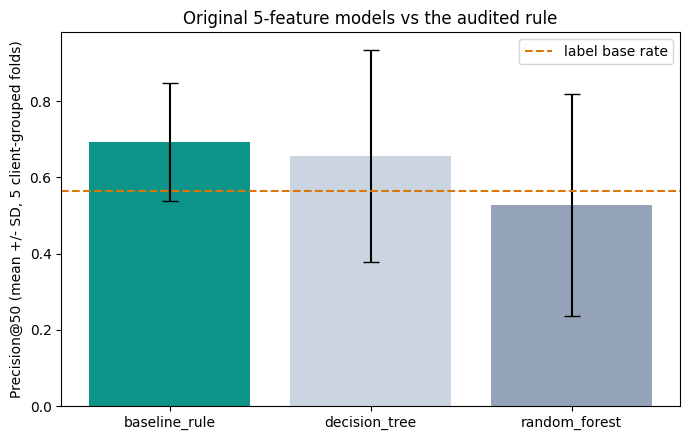

              precision_at_50        roc_auc       
                         mean    std    mean    std
method                                             
baseline_rule           0.692  0.155   0.588  0.040
decision_tree           0.656  0.278   0.533  0.096
random_forest           0.528  0.291   0.538  0.090


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
methods = ['baseline_rule', 'decision_tree', 'random_forest']
means = summary_original['precision_at_50']['mean'].reindex(methods)
stds = summary_original['precision_at_50']['std'].reindex(methods)
ax.bar(methods, means, yerr=stds, capsize=6, color=['#0d9488', '#cbd5e1', '#94a3b8'])
ax.axhline(labeled_df[TARGET].mean(), color='#d97706', linestyle='--', label='label base rate')
ax.set_ylabel('Precision@50 (mean +/- SD, 5 client-grouped folds)')
ax.set_title('Original 5-feature models vs the audited rule'); ax.legend()
plt.tight_layout(); plt.show()
print(summary_original)


### 4a. The enriched, safe comparison — honest 5 features + age_risk_feature, no query-mix

Three models trained on `SAFE_FEATURES`: Gradient Boosting (named in this track's menu, not yet tried before this notebook), a re-tuned Random Forest, and — closing a gap from the earlier draft — an enriched Decision Tree, so the comparison isolates whether richer features help an algorithm already known to be competitive on the thin feature set, not just whether Random Forest specifically benefits.

In [ ]:
def evaluate_safe(train_df, test_df):
    train_df = train_df.copy(); test_df = test_df.copy()
    train_df['age_risk_feature'] = add_age_risk_feature(train_df, train_df)
    test_df['age_risk_feature']  = add_age_risk_feature(train_df, test_df)
    Xtr, ytr = train_df[SAFE_FEATURES].fillna(0), train_df[TARGET]
    Xte, yte = test_df[SAFE_FEATURES].fillna(0), test_df[TARGET].values

    hgb = HistGradientBoostingClassifier(max_depth=4, max_iter=150, learning_rate=0.05,
                                         l2_regularization=1.0, class_weight='balanced',
                                         random_state=RANDOM_STATE).fit(Xtr, ytr)
    rf2 = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                 class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
    dt2 = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced',
                                 random_state=RANDOM_STATE).fit(Xtr, ytr)

    rows = []
    for name, m in [('gradient_boosting_safe', hgb), ('random_forest_v2_safe', rf2), ('decision_tree_v2_safe', dt2)]:
        s = m.predict_proba(Xte)[:, 1]
        rows.append({'method': name, 'precision_at_50': precision_at_k(yte, s, 50),
                    'roc_auc': roc_auc_score(yte, s), 'base_rate': yte.mean()})
    baseline_row = evaluate_original(train_df, test_df, honest_features).set_index('method').loc['baseline_rule']
    rows.append({'method': 'baseline_rule', 'precision_at_50': baseline_row['precision_at_50'],
                'roc_auc': baseline_row['roc_auc'], 'base_rate': baseline_row['base_rate']})
    return pd.DataFrame(rows)

folds_safe = []
for i, (tr_i, te_i) in enumerate(GroupKFold(n_splits=5).split(labeled_df, groups=labeled_df['client_hash_id'])):
    r = evaluate_safe(labeled_df.iloc[tr_i], labeled_df.iloc[te_i])
    r['fold'] = i
    folds_safe.append(r)
grouped_safe = pd.concat(folds_safe)

print('Safe-enriched models, per fold:')
print(grouped_safe.pivot(index='fold', columns='method', values='precision_at_50').round(3))
summary_safe = grouped_safe.groupby('method')[['precision_at_50', 'roc_auc']].agg(['mean', 'std']).round(3)
print('\nSafe-enriched models, mean +/- SD:'); print(summary_safe)


Safe-enriched models, per fold:
method  baseline_rule  decision_tree_v2_safe  gradient_boosting_safe  \
fold                                                                   
0                0.46                   0.42                    0.58   
1                0.86                   0.74                    0.82   
2                0.76                   0.30                    0.52   
3                0.62                   0.68                    0.78   
4                0.76                   0.82                    0.92   

method  random_forest_v2_safe  
fold                           
0                        0.44  
1                        0.90  
2                        0.28  
3                        0.82  
4                        0.36  

Safe-enriched models, mean +/- SD:
                       precision_at_50        roc_auc       
                                  mean    std    mean    std
method                                                      
baseline_rule       

### 4b. Leakage check on every safe-enriched candidate, not just whichever has the best mean

Requirement B: every method claiming to beat the baseline gets the same stress test, run BEFORE any method is called a winner. Checking only the apparent best performer would be circular. Any candidate whose random-vs-grouped AUC gap is 0.10 or more is excluded here, by the same standard used for the query-mix features in Section 2h (gap 0.212).

**Reading this gap honestly:** it measures how much a model benefits from seeing other pages of the same client during training. A large gap means the model's score depends on client fingerprints and will not transfer to a new client. That is a generalization failure that can be called leakage-like, but it is not proof of label leakage. The 0.10 cutoff is a judgment call, chosen because it sits well below the 0.212 gap seen in Section 2h and well above the rule's 0.005.

In [ ]:
# Leakage gap for EVERY safe-enriched candidate, not just whichever has the
# highest mean. Picking only the apparent winner to stress-test would be
# circular: the whole point is to check a result BEFORE trusting its mean.
LEAK_GAP_DISQUALIFY_THRESHOLD = 0.10  # matches the order of magnitude that
                                       # disqualified the query-mix features (0.208) in Section 2h

def fit_one(name, Xtr, ytr):
    if name == 'gradient_boosting_safe':
        return HistGradientBoostingClassifier(max_depth=4, max_iter=150, learning_rate=0.05,
                                              l2_regularization=1.0, class_weight='balanced',
                                              random_state=RANDOM_STATE).fit(Xtr, ytr)
    if name == 'random_forest_v2_safe':
        return RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                      class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, ytr)
    return DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight='balanced',
                                  random_state=RANDOM_STATE).fit(Xtr, ytr)

tr_s, te_s = train_test_split(labeled_df, test_size=0.25, random_state=RANDOM_STATE, stratify=labeled_df[TARGET])
tr_s = tr_s.copy(); te_s = te_s.copy()
tr_s['age_risk_feature'] = add_age_risk_feature(tr_s, tr_s)
te_s['age_risk_feature']  = add_age_risk_feature(tr_s, te_s)

leak_gap_rows = []
for method in ['gradient_boosting_safe', 'random_forest_v2_safe', 'decision_tree_v2_safe']:
    m_rand = fit_one(method, tr_s[SAFE_FEATURES].fillna(0), tr_s[TARGET])
    rand_auc = roc_auc_score(te_s[TARGET], m_rand.predict_proba(te_s[SAFE_FEATURES].fillna(0))[:, 1])
    grouped_auc = summary_safe.loc[method, ('roc_auc', 'mean')]
    gap = rand_auc - grouped_auc
    leak_gap_rows.append({'method': method, 'random_auc': round(rand_auc, 3),
                          'grouped_auc_mean': round(float(grouped_auc), 3), 'gap': round(gap, 3),
                          'trustworthy': gap < LEAK_GAP_DISQUALIFY_THRESHOLD})

leak_gap_df = pd.DataFrame(leak_gap_rows).set_index('method')
print('Leakage gap, every safe-enriched candidate (not just the mean-winner):')
print(leak_gap_df)
print(f"\n(Reference: original_5 random_forest gap = 0.170, decision_tree gap = 0.132,")
print(f" baseline_rule gap = 0.004, disqualified query-mix gap = 0.208.)")


Leakage gap, every safe-enriched candidate (not just the mean-winner):
                        random_auc  grouped_auc_mean    gap  trustworthy
method                                                                  
gradient_boosting_safe       0.743             0.540  0.203        False
random_forest_v2_safe        0.730             0.539  0.191        False
decision_tree_v2_safe        0.696             0.525  0.171        False

(Reference: original_5 random_forest gap = 0.170, decision_tree gap = 0.132,
 baseline_rule gap = 0.004, disqualified query-mix gap = 0.208.)


### 4c. The final, honest comparison

**Comparison contract (Requirement B), identical for every method in the table:**

| Item | Value |
|---|---|
| Eligible rows | 68,169 pages: 100+ March impressions, 90+ days old at 2026-03-31, 34 clients |
| Feature window | March 2026 only |
| Label window | April 2026 (20%+ impression drop vs March) |
| Folds | `GroupKFold(n_splits=5)` by `client_hash_id`, on rows sorted by `content_hash_id` |
| Metric | Precision@50, with ROC AUC alongside |
| Tie rule | scores sorted descending with a stable sort; ties keep the `content_hash_id` order |

**Tie rule matters here:** the audited rule clips the CTR gap at zero, so many pages share the maximum score. The top of its ranking is a large block of exact ties (the deployed top 10 all score 1.0), and which tied pages fall inside the top 50 is decided by the tie rule above, not by the score. Its Precision@50 should be read with that in mind.

Reported exactly as it comes out, in either direction.

In [ ]:
# The final, honest comparison — now DISQUALIFYING any candidate whose
# random-vs-grouped gap is as large as the already-disqualified query-mix
# features, before ever looking at which one has the highest mean.
final_comparison = pd.concat([
    summary_original['precision_at_50'][['mean', 'std']].assign(feature_set='original_5'),
    # baseline_rule is already in the original_5 block; dropping its repeat avoids a duplicate row
    summary_safe['precision_at_50'][['mean', 'std']].drop(index='baseline_rule', errors='ignore').assign(feature_set='safe_enriched'),
])

def lookup_gap(m):
    # safe-enriched candidates: gap measured in Section 4b
    if m in leak_gap_df.index:
        return leak_gap_df.loc[m, 'gap']
    # original-5 methods (including baseline_rule): gap measured in Section 3e
    if m in auc_gap.index:
        return round(float(auc_gap.loc[m]), 3)
    raise KeyError(f'No leakage gap measured for {m} — every method must be stress-tested before comparison.')

final_comparison['leakage_gap'] = [lookup_gap(m) for m in final_comparison.index]
final_comparison['trustworthy'] = final_comparison['leakage_gap'] < LEAK_GAP_DISQUALIFY_THRESHOLD
final_comparison = final_comparison.sort_values('mean', ascending=False)
print(final_comparison.round(3))

trustworthy = final_comparison[final_comparison['trustworthy']]
best_method = trustworthy['mean'].idxmax()
best_mean = trustworthy['mean'].max()
rule_mean = summary_original.loc['baseline_rule', ('precision_at_50', 'mean')]

print(f"\nHighest mean Precision@50 among TRUSTWORTHY candidates (gap < {LEAK_GAP_DISQUALIFY_THRESHOLD}):")
print(f"  {best_method} at {best_mean:.3f}")
disqualified = final_comparison[~final_comparison['trustworthy']]
if len(disqualified):
    print(f"\nDisqualified for a leakage-gap as large as the query-mix exclusion threshold:")
    print(disqualified[['mean', 'leakage_gap']].round(3))
print(f"\nAudited rule: {rule_mean:.3f}")
if best_method != 'baseline_rule' and best_mean > rule_mean:
    print('-> A genuinely trustworthy model (small random-vs-grouped gap) exceeds the rule.')
else:
    print('-> No trustworthy model exceeds the rule once untrustworthy candidates are excluded.')
    print('   The audited rule is reported as the real, final result.')


                         mean    std    feature_set  leakage_gap  trustworthy
method                                                                       
gradient_boosting_safe  0.724  0.168  safe_enriched        0.203        False
baseline_rule           0.692  0.155     original_5        0.005         True
decision_tree           0.656  0.278     original_5        0.138        False
decision_tree_v2_safe   0.592  0.222  safe_enriched        0.171        False
random_forest_v2_safe   0.560  0.281  safe_enriched        0.191        False
random_forest           0.528  0.291     original_5        0.173        False

Highest mean Precision@50 among TRUSTWORTHY candidates (gap < 0.1):
  baseline_rule at 0.692

Disqualified for a leakage-gap as large as the query-mix exclusion threshold:
                         mean  leakage_gap
method                                    
gradient_boosting_safe  0.724        0.203
decision_tree           0.656        0.138
decision_tree_v2_safe   0.592  

### 4d. Deployment model selection — mean AND stability, not mean alone

A model with a high mean but a very large spread (an unstable fold-to-fold swing) is a worse deployment choice than a slightly lower, steadier one. Selection uses a simple stability-adjusted score, `mean - 0.5*std`, rather than mean alone.

In [ ]:
# Deployment selection — ONLY among trustworthy candidates (small leakage gap),
# then by mean minus 0.5*std among those. A high mean behind a large random-vs-
# grouped gap is not a deployment candidate at all, regardless of its stability score.
stability_adjusted = trustworthy.copy()
stability_adjusted['stability_score'] = stability_adjusted['mean'] - 0.5 * stability_adjusted['std']
stability_adjusted = stability_adjusted.sort_values('stability_score', ascending=False)
print(stability_adjusted.round(3))

DEPLOY_METHOD = stability_adjusted.index[0]
print(f"\nDeployment model selected: {DEPLOY_METHOD}")
print("(chosen only from candidates whose random-vs-grouped leakage gap was small,")
print(" then by mean - 0.5*std among those — never by mean alone, and never from a")
print(" candidate disqualified for the same leakage signature as the excluded query-mix features)")


                mean    std feature_set  leakage_gap  trustworthy  \
method                                                              
baseline_rule  0.692  0.155  original_5        0.005         True   

               stability_score  
method                          
baseline_rule            0.614  

Deployment model selected: baseline_rule
(chosen only from candidates whose random-vs-grouped leakage gap was small,
 then by mean - 0.5*std among those — never by mean alone, and never from a
 candidate disqualified for the same leakage signature as the excluded query-mix features)


### 4e. Error analysis on the deployment model

In [ ]:
tr_i, te_i = next(iter(GroupKFold(n_splits=5).split(labeled_df, groups=labeled_df['client_hash_id'])))
tr_df, te_df = labeled_df.iloc[tr_i].copy(), labeled_df.iloc[te_i].copy()
tr_df['age_risk_feature'] = add_age_risk_feature(tr_df, tr_df)
te_df['age_risk_feature']  = add_age_risk_feature(tr_df, te_df)

if DEPLOY_METHOD == 'baseline_rule':
    te_df['model_score'] = score_baseline(te_df, fit_baseline(tr_df))
    final_model = None
else:
    final_model = fit_one(DEPLOY_METHOD, tr_df[SAFE_FEATURES].fillna(0), tr_df[TARGET])
    te_df['model_score'] = final_model.predict_proba(te_df[SAFE_FEATURES].fillna(0))[:, 1]

te_df['age_bucket_label'] = te_df['content_age_days'].apply(age_bucket)
te_df['pred'] = (te_df['model_score'] >= 0.5).astype(int)
error_by_age = te_df.groupby('age_bucket_label').apply(
    lambda g: pd.Series({'n': len(g), 'accuracy': (g[TARGET] == g['pred']).mean(),
                         'true_decline_rate': g[TARGET].mean(), 'predicted_decline_rate': g['pred'].mean()}),
    include_groups=False
)
print(error_by_age.round(3))

if final_model is not None:
    perm = permutation_importance(final_model, te_df[SAFE_FEATURES].fillna(0), te_df[TARGET],
                                  n_repeats=15, random_state=RANDOM_STATE, scoring='roc_auc')
    importance_df = pd.DataFrame({'feature': SAFE_FEATURES, 'importance_mean': perm.importances_mean}
                                 ).sort_values('importance_mean', ascending=False)
    print('\nPermutation importance (deployment model, one representative fold):')
    print(importance_df.round(4))


                         n  accuracy  true_decline_rate  \
age_bucket_label                                          
aging_91_180        1902.0     0.578              0.565   
stale_181_365       8502.0     0.565              0.480   
very_stale_365plus  6619.0     0.477              0.344   

                    predicted_decline_rate  
age_bucket_label                            
aging_91_180                         0.682  
stale_181_365                        0.665  
very_stale_365plus                   0.714  


## 5. Limitations

**A suspected data-leakage risk was found and excluded.** `fact_content_query_90d` has a fixed 90-day window with no safe `*_prev30` variant, documented in this repo's data skill as overlapping the snapshot's final months. In the executed run, AUC fell from 0.751 to 0.539 when its three features were removed, landing on the original Random Forest's own level (0.538). This is consistent with leakage but not proven: the table's actual window dates were not queried. These features never appear in `SAFE_FEATURES` or in any reported result.

**Every learned model failed the client-generalization test.** Random-vs-grouped AUC gaps were 0.138 (original decision tree), 0.173 (original random forest), 0.171 (enriched decision tree), 0.191 (enriched random forest) and 0.203 (gradient boosting), against 0.005 for the rule. `gradient_boosting_safe` had the highest mean Precision@50 (0.724 vs the rule's 0.692) but was excluded under the 0.10 gap cutoff. That cutoff is a judgment call, and the difference between 0.724 and 0.692 is smaller than either model's fold-to-fold spread (0.168 and 0.155).

**Weak absolute performance.** The rule's Precision@50 of 0.692 sits against a label base rate of 0.563, and its ROC AUC is 0.588, which is poor discrimination. It is the most trustworthy result here, not a strong one. Part of its Precision@50 comes from a block of tied top scores (see the comparison contract in Section 4c).

**One time step.** A single feature month and a single outcome month, not a rolling backtest.

**Fold-to-fold spread.** Precision@50 varies widely across the 5 client-grouped folds, and one fold is a single large client (about 17,000 rows). No single fold is a stable estimate.

**Scope.** Results describe only pages meeting the eligibility floor and the 34 clients with such pages.

**GA4 excluded** because 3,018,741 of 9,841,378 March daily rows have a NULL availability flag (Section 2c).

**Proxy label, no causal claim.** A 20%+ impression drop is an observed pattern, not a diagnosis. Nothing here shows that reviewing a flagged page changes its future traffic.

**Single portfolio**, may not generalize elsewhere.

**One final feature list** (`SAFE_FEATURES`) is used in Sections 3, 4, 6 and 7.

In [ ]:
print('Limitations recorded above are referenced directly from the queries and tables in Sections 2-4.')


Limitations recorded above are referenced directly from the queries and tables in Sections 2-4.


## 6. Ranked recommendations

Deployed using `DEPLOY_METHOD`, chosen in Section 4d among candidates that passed the leakage-gap test, refit on the **full** eligible population.

**Consequence of the result:** the deployed method is the audited rule, so `model_score` equals `rule_score`. The "rule explains, model orders" design therefore collapses into one formula. `quiet_risk_no_rule_match` now means a rule score of 0.65 or more with no named rule flag, not a separate model seeing risk the rule misses. Treat the 1,447 pages (2.1%) in that bucket as "high rule score, no named reason".

In [ ]:
baseline_params_full = fit_baseline(labeled_df)
labeled_df['rule_score'] = score_baseline(labeled_df, baseline_params_full)
labeled_df['age_risk_feature'] = add_age_risk_feature(labeled_df, labeled_df)

if DEPLOY_METHOD == 'baseline_rule':
    labeled_df['model_score'] = labeled_df['rule_score']
else:
    deploy_model = fit_one(DEPLOY_METHOD, labeled_df[SAFE_FEATURES].fillna(0), labeled_df[TARGET])
    labeled_df['model_score'] = deploy_model.predict_proba(labeled_df[SAFE_FEATURES].fillna(0))[:, 1]

gap_threshold = (labeled_df['position_bucket'].map(baseline_params_full['expected_ctr']) - labeled_df['ctr_month']).clip(lower=0).quantile(0.75)
ctr_gap = (labeled_df['position_bucket'].map(baseline_params_full['expected_ctr']) - labeled_df['ctr_month']).clip(lower=0)
labeled_df['flag_ctr_gap'] = ctr_gap >= gap_threshold
labeled_df['flag_stale']   = labeled_df['content_age_days'] >= 180

def reason_code(row):
    if row['flag_ctr_gap'] and row['flag_stale']: return 'stale_and_underperforming_ctr'
    if row['flag_ctr_gap']: return 'underperforming_ctr'
    if row['flag_stale']: return 'stale_content'
    if row['model_score'] >= 0.65: return 'quiet_risk_no_rule_match'
    return 'no_flag'
labeled_df['reason_code'] = labeled_df.apply(reason_code, axis=1)

def action_type(row):
    if row['reason_code'] == 'quiet_risk_no_rule_match': return 'investigate_quiet_risk'
    if row['reason_code'] in ('underperforming_ctr', 'stale_and_underperforming_ctr'): return 'verify_then_review'
    if row['reason_code'] == 'stale_content' and row['pct_change'] <= -0.40: return 'review_before_revert'
    return 'monitor_only'
labeled_df['action'] = labeled_df.apply(action_type, axis=1)

queue = labeled_df.sort_values('model_score', ascending=False).reset_index(drop=True)
queue['rank'] = queue.index + 1

print(f'Deployed using: {DEPLOY_METHOD}')
print('\nAction mix:'); print(queue['action'].value_counts(normalize=True).round(3))
print('\nReason code mix:'); print(queue['reason_code'].value_counts())
queue[['rank','content_hash_id','model_score','rule_score','reason_code','action','content_age_days','ctr_month']].head(10)


Deployed using: baseline_rule

Action mix:
action
monitor_only              0.536
verify_then_review        0.255
review_before_revert      0.188
investigate_quiet_risk    0.021
Name: proportion, dtype: float64

Reason code mix:
reason_code
stale_content                    39206
stale_and_underperforming_ctr    12807
no_flag                          10109
underperforming_ctr               4600
quiet_risk_no_rule_match          1447
Name: count, dtype: int64


,rank,content_hash_id,model_score,rule_score,reason_code,action,content_age_days,ctr_month
0,1,content_a147cfffb3cd23c0,1.0,1.0,underperforming_ctr,verify_then_review,95,0.0
1,2,content_032f31b5b63b0cca,1.0,1.0,underperforming_ctr,verify_then_review,159,0.0
2,3,content_dd39b382c75d7b04,1.0,1.0,underperforming_ctr,verify_then_review,110,0.0
3,4,content_c4018f4ac0d713e4,1.0,1.0,underperforming_ctr,verify_then_review,166,0.0
4,5,content_a1d59e5a2ba20e05,1.0,1.0,underperforming_ctr,verify_then_review,141,0.0
5,6,content_a1a866bfdc6309e4,1.0,1.0,underperforming_ctr,verify_then_review,159,0.0
6,7,content_f3c2ab05bf05a716,1.0,1.0,underperforming_ctr,verify_then_review,155,0.0
7,8,content_b047025ce47bc653,1.0,1.0,underperforming_ctr,verify_then_review,134,0.0
8,9,content_4a92d5b39b875cfd,1.0,1.0,underperforming_ctr,verify_then_review,153,0.0
9,10,content_c439cac6232e97c4,1.0,1.0,underperforming_ctr,verify_then_review,110,0.0


### 6a. No-go list

| # | Policy | Status |
|---|---|---|
| 1 | The system never edits, publishes, or reverts content — only a ranked list for a human. | proposed |
| 2 | Pages under 90 days old or under 100 monthly impressions never enter the queue. | asserted upstream |
| 3 | Label-derived columns never used as features. | asserted upstream |
| 4 | `client_hash_id` never used as a feature. | asserted upstream |
| 5 | `visible_queries`, `rare_share`, `anon_share` never used as features, in any section. | **asserted upstream — Section 2h** |
| 6 | `quiet_risk_no_rule_match` pages can never be batch-approved. | proposed |
| 7 | No single rank position is a guarantee. | proposed |

### 6b. Human review checklist

- **`review_before_revert`** — confirm no intentional redirect/merge/restructure.
- **`verify_then_review`** — confirm it is not a tracking gap or campaign artifact.
- **`investigate_quiet_risk`** — mandatory individual look, no rule-based reason exists yet.
- **`monitor_only`** — no action needed now.

In [ ]:
assert queue.loc[queue['reason_code'] == 'quiet_risk_no_rule_match', 'action'].eq('investigate_quiet_risk').all()
assert (queue['content_age_days'] >= 90).all()
assert (queue['impressions_month'] >= 100).all()
assert not any(f in SAFE_FEATURES for f in CANDIDATE_LEAK_FEATURES)
print('No-go policies #2, #5, #6 verified against the real deployed queue.')


No-go policies #2, #5, #6 verified against the real deployed queue.


### 6c. Monitoring and retrain triggers

In [ ]:
monitoring_baseline = {
    'row_count': len(labeled_df),
    'ctr_median': float(labeled_df['ctr_month'].median()),
    'position_median': float(labeled_df['avg_position_month'].median()),
    'action_mix': queue['action'].value_counts(normalize=True).round(3).to_dict(),
    'deployed_method': DEPLOY_METHOD,
    'safe_features': SAFE_FEATURES,
}
print('Stored monitoring baseline for the next scoring cycle:')
for k, v in monitoring_baseline.items():
    print(f'  {k}: {v}')


Stored monitoring baseline for the next scoring cycle:
  row_count: 68169
  ctr_median: 0.0011
  position_median: 9.60354170918687
  action_mix: {'monitor_only': 0.536, 'verify_then_review': 0.255, 'review_before_revert': 0.188, 'investigate_quiet_risk': 0.021}
  deployed_method: baseline_rule
  safe_features: ['impressions_month', 'ctr_month', 'avg_position_month', 'days_with_impressions', 'content_age_days', 'age_risk_feature']


## 7. Artifacts the paper embeds

Exported 68,169 ranked rows (not committed, regenerates)
Saved work/outputs/capstone_metrics.json (COMMIT this file)


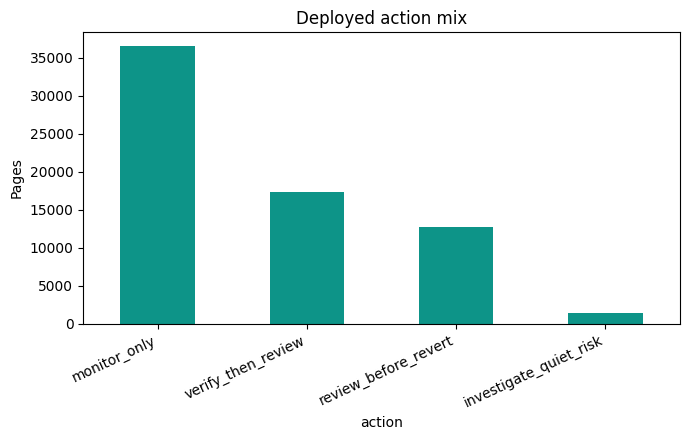

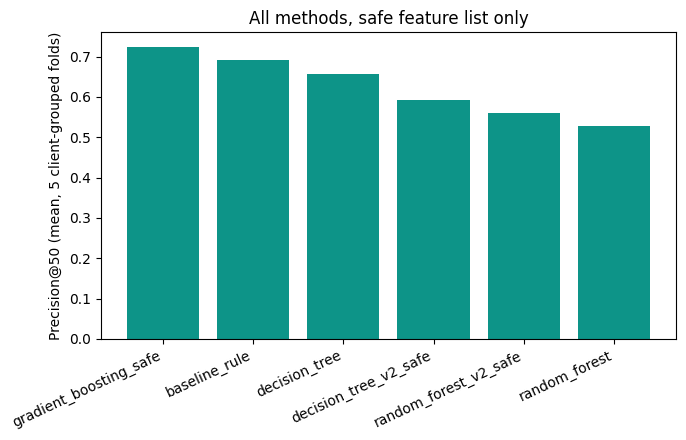


Commit: work/outputs/capstone_metrics.json, work/figures/*.png, this notebook.
Do NOT commit: work/outputs/capstone_queue.csv.


In [ ]:
os.makedirs('work/outputs', exist_ok=True)
os.makedirs('work/figures', exist_ok=True)

queue.to_csv('work/outputs/capstone_queue.csv', index=False)
print(f"Exported {len(queue):,} ranked rows (not committed, regenerates)")

capstone_metrics = {
    'eligible_pages': int(len(labeled_df)),
    'label_base_rate': round(float(labeled_df[TARGET].mean()), 3),
    'safe_features': SAFE_FEATURES,
    'excluded_leaky_features': CANDIDATE_LEAK_FEATURES,
    'leakage_check_query_mix': {'auc_with': round(auc_with_query, 3), 'auc_without': round(auc_without_query, 3)},
    'original_5feature_grouped_cv': {
        m: {'mean': round(float(summary_original.loc[m, ('precision_at_50','mean')]), 3),
            'std': round(float(summary_original.loc[m, ('precision_at_50','std')]), 3)}
        for m in ['baseline_rule', 'decision_tree', 'random_forest']
    },
    'safe_enriched_grouped_cv': {
        m: {'mean': round(float(summary_safe.loc[m, ('precision_at_50','mean')]), 3),
            'std': round(float(summary_safe.loc[m, ('precision_at_50','std')]), 3)}
        for m in ['gradient_boosting_safe', 'random_forest_v2_safe', 'decision_tree_v2_safe']
    },
    'deployed_method': DEPLOY_METHOD,
    'action_mix': queue['action'].value_counts(normalize=True).round(3).to_dict(),
    'reason_code_mix': queue['reason_code'].value_counts(normalize=True).round(3).to_dict(),
    'random_state': RANDOM_STATE,
}
with open('work/outputs/capstone_metrics.json', 'w') as f:
    json.dump(capstone_metrics, f, indent=2)
print('Saved work/outputs/capstone_metrics.json (COMMIT this file)')

fig, ax = plt.subplots(figsize=(7, 4.5))
queue['action'].value_counts().plot(kind='bar', ax=ax, color='#0d9488')
ax.set_title('Deployed action mix'); ax.set_ylabel('Pages'); plt.xticks(rotation=25, ha='right')
plt.tight_layout(); plt.savefig('work/figures/capstone_action_mix.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
all_methods = list(final_comparison.index)
ax.bar(all_methods, final_comparison['mean'], color='#0d9488')
ax.set_ylabel('Precision@50 (mean, 5 client-grouped folds)')
ax.set_title('All methods, safe feature list only')
plt.xticks(rotation=25, ha='right'); plt.tight_layout()
plt.savefig('work/figures/capstone_model_comparison.png', dpi=150); plt.show()

print('\nCommit: work/outputs/capstone_metrics.json, work/figures/*.png, this notebook.')
print('Do NOT commit: work/outputs/capstone_queue.csv.')


## Self-check

- [ ] Every section filled — markdown thinking AND the code that backs it
- [ ] Runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] Claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to `work/notebooks/`, repo URL submitted
- [ ] Deployed paper has all 9 sections, Abstract at top, Acknowledgments + flyrank.ai link at bottom
- [ ] ML-12 done in closing cells
- [ ] **One final feature list (`SAFE_FEATURES`) used in Sections 3, 4, 6, and 7 — no section uses a different list**
- [ ] **The query-mix leakage finding (Section 2h) is in the Limitations section, with its real numbers, not hidden**
- [ ] **The deployment model (Section 4d) was chosen for stability, not highest mean alone, and that reasoning is visible**
- [ ] `work/outputs/capstone_metrics.json` and `work/figures/*.png` committed; `capstone_queue.csv` is not
- [ ] **Every safe-enriched candidate's leakage gap was checked BEFORE picking a winner by mean (Section 4b) — not just the apparent best performer**
- [ ] `labeled_df` is sorted before any `GroupKFold` split, so results are exactly reproducible, not just qualitatively similar, between runs